#Criteo Uplift Prediction

Measuring overall conversion rate is sometimes not enough. An uplift model allows you to see the impact of an ad on a person to person level. The goal is to identify the 'Persuadables' - the people who will buy something only if they are treated (exposed to the ad). This allows specific targeting that doesn't waste time on people who will buy the product anyway (Sure Things) or people who won't buy no matter what (Lost Causes), and avoid exposing the ad to someone who won't buy it because they were shown the ad (Do-Not_Disturbs/Sleeping-dogs).

#About the Dataset

From the Criteo AI Lab's Criteo Uplift Modeling Dataset webpage -

Data description

This dataset is constructed by assembling data resulting from several incrementality tests, a particular randomized trial procedure where a random part of the population is prevented from being targeted by advertising. it consists of 25M rows, each one representing a user with 11 features, a treatment indicator and 2 labels (visits and conversions).

Fields

Here is a detailed description of the fields (they are comma-separated in the file):

    f0, f1, f2, f3, f4, f5, f6, f7, f8, f9, f10, f11: feature values (dense, float)
    treatment: treatment group (1 = treated, 0 = control)
    conversion: whether a conversion occured for this user (binary, label)
    visit: whether a visit occured for this user (binary, label)
    exposure: treatment effect, whether the user has been effectively exposed (binary)


Features in real life could be things like demographics, ad platform, purchase history, device, interests etc.

visit - if the person visited the webiste
conversion - if the person made a purchase on the website
exposure - if the person actually saw that ad (different from assigned treatment group)

Feature values are anonymized and numeric to protect user privacy, so this model will be predictive but not interpretable. In real life the features would have definitions to help guide actual targeting.

#Set Up
Pulling in data from Kaggle

In [1]:
import os, json
from google.colab import userdata

In [2]:
# Configure Kaggle credentials (run once per session)
# Add KAGGLE_USERNAME and KAGGLE_KEY to Colab Secrets (🔑 icon in the left sidebar) -- do not hardcode them in the notebook!
os.makedirs('/root/.kaggle', exist_ok=True)
creds = {
    "username": userdata.get('KAGGLE_USERNAME'),
    "key":      userdata.get('KAGGLE_KEY'),
}
with open('/root/.kaggle/kaggle.json', 'w') as f:
    json.dump(creds, f)
!chmod 600 /root/.kaggle/kaggle.json

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("arashnic/uplift-modeling")

print("Path to dataset files:", path)

100%|██████████| 324M/324M [00:02<00:00, 144MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/arashnic/uplift-modeling/versions/1


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from statsmodels.stats.proportion import proportions_ztest

In [5]:
df = pd.read_csv(os.path.join(path, "criteo-uplift-v2.1.csv"))

#EDA

In [6]:
df.head()

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.616365,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
1,12.616365,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
2,12.616365,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
3,12.616365,10.059654,9.002801,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
4,12.616365,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0


In [7]:
df.shape

(13979592, 16)

13979592 samples

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13979592 entries, 0 to 13979591
Data columns (total 16 columns):
 #   Column      Dtype  
---  ------      -----  
 0   f0          float64
 1   f1          float64
 2   f2          float64
 3   f3          float64
 4   f4          float64
 5   f5          float64
 6   f6          float64
 7   f7          float64
 8   f8          float64
 9   f9          float64
 10  f10         float64
 11  f11         float64
 12  treatment   int64  
 13  conversion  int64  
 14  visit       int64  
 15  exposure    int64  
dtypes: float64(12), int64(4)
memory usage: 1.7 GB


In [9]:
df.isna().sum()

,0
f0,0
f1,0
f2,0
f3,0
f4,0
f5,0
f6,0
f7,0
f8,0
f9,0


##Looking for Class Imbalances

In [10]:
df['treatment'].value_counts(normalize=True)

,proportion
treatment,
1,0.85
0,0.15


There is disproportionally more users in the treatment group than the control group. I think this is so that the treatment group have more chances to actually be exposed to the ad once targeted. The control group estimates will just be noisier since there are less rows.

In [11]:
df['exposure'].value_counts(normalize=True)

,proportion
exposure,
0,0.969369
1,0.030631


In [12]:
df['visit'].value_counts(normalize=True)

,proportion
visit,
0,0.953008
1,0.046992


In [13]:
df['conversion'].value_counts(normalize=True)

,proportion
conversion,
0,0.997083
1,0.002917


In [14]:
print(df['treatment'].mean())
print(df['visit'].mean())
print(df['conversion'].mean())
print(df['exposure'].mean())

0.8500001287591226
0.046992000911042324
0.002916680257907384
0.03063122299992732


Noting the class imbalance of the conversion and visit rates.

###Getting the conversion, visit, and exposure rates by treatment group

This works because getting the mean of binaries will give you the rate. For example - group 1 had 10 0s and group 2 had 20 1s - (0+20)/30 = ~66.67%

In [15]:
df.groupby('treatment')[['visit', 'conversion', 'exposure']].mean()

,visit,conversion,exposure
treatment,,,
0,0.038201,0.001938,0.000000
1,0.048543,0.003089,0.036037


There are more visits than conversions, so I will model based on visits first. Also wanted to note that only 3.6% of the treament group was actually exposed to the ad. This is a limitation but we are trying to predict who is worth targeting, not who will do something once exposed to the ad. Plus, a person actually seeing the ad even if targeted is out of the advertiser's control, and depends on extra factors like how much the person is scrolling or ad bidding outcomes. You can't gaurantee that an impression will show up for a specific person, ad bidding doesn't work that way.

##A/B Test Analysis

###SMD Calculation (Balance Check)

Crucial question - were the treatment and control groups actually assigned at random? Both groups need a similar distribution across features, so we will check that through SMD (standardized mean difference). Anything under 0.1 I will count as balanced.

In [16]:
feature_cols = [f'f{i}' for i in range(12)] #list out the 12 feature columns

means = df.groupby('treatment')[feature_cols].mean() #average of feature, grouped by treatment
stds = df.groupby('treatment')[feature_cols].std() #standard deviation of each feature

pooled_std = ((stds.loc[1] ** 2 + stds.loc[0] ** 2) / 2) ** 0.5 #calculates denominator for SMD

smd = (means.loc[1] - means.loc[0]) / pooled_std

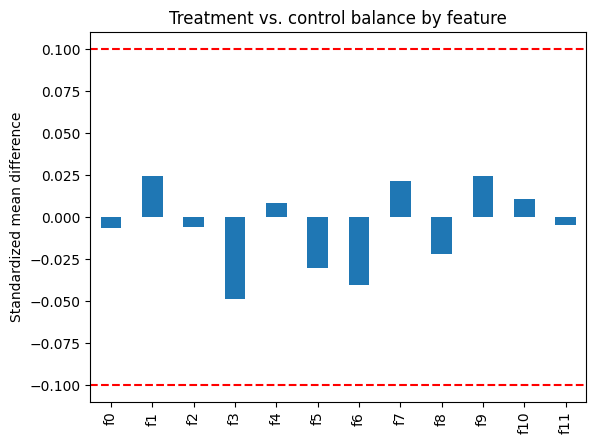

In [17]:
smd.plot(kind='bar')
plt.axhline(y=0.1, color='red', linestyle='--')
plt.axhline(y=-0.1, color='red', linestyle='--')
plt.ylabel('Standardized mean difference')
plt.title('Treatment vs. control balance by feature')
plt.show()

In [18]:
print(smd)
print(smd.abs().max())

f0    -0.006866
f1     0.023994
f2    -0.006241
f3    -0.048836
f4     0.007966
f5    -0.030557
f6    -0.040448
f7     0.021270
f8    -0.022433
f9     0.024001
f10    0.010563
f11   -0.005160
dtype: float64
0.04883634021547923


Features are balanced within the threshold! f3 has the highest imbalance.

###Confidence Intervals (Main result of A/B test)

Does targeting people with the ad change their behavior at all?

In [19]:
outcome = 'visit'

n_t = (df['treatment'] == 1).sum() #counts treatments
n_c = (df['treatment'] == 0).sum() #counts control

rate_t = df.loc[df['treatment'] == 1, outcome].mean() #counts visits based on treatment
rate_c = df.loc[df['treatment'] == 0, outcome].mean()

lift = rate_t - rate_c

se = (rate_t * (1 - rate_t) / n_t + rate_c * (1 - rate_c) / n_c) ** 0.5 #standard error of lift, how noisy it is

ci_low = lift - 1.96 * se #based on 95% CI
ci_high = lift + 1.96 * se

print(f"Treatment {outcome} rate = {rate_t: .4%}")
print(f"Control {outcome} rate = {rate_c:.4%}")
print(f"Lift (percentage points) = {lift:.4%}")
print(f"95% CI = [{ci_low:.4%}, {ci_high:.4%}]")
print(f"Relative lift = {lift / rate_c:.1%}")

Treatment visit rate =  4.8543%
Control visit rate = 3.8201%
Lift (percentage points) = 1.0342%
95% CI = [1.0056%, 1.0629%]
Relative lift = 27.1%


In [20]:
outcome = 'conversion'

n_t = (df['treatment'] == 1).sum()
n_c = (df['treatment'] == 0).sum()

rate_t = df.loc[df['treatment'] == 1, outcome].mean()
rate_c = df.loc[df['treatment'] == 0, outcome].mean()

lift = rate_t - rate_c

se = (rate_t * (1 - rate_t) / n_t + rate_c * (1 - rate_c) / n_c) ** 0.5

ci_low = lift - 1.96 * se
ci_high = lift + 1.96 * se

print(f"Treatment {outcome} rate = {rate_t: .4%}")
print(f"Control {outcome} rate = {rate_c:.4%}")
print(f"Lift (percentage points) = {lift:.4%}")
print(f"95% CI = [{ci_low:.4%}, {ci_high:.4%}]")
print(f"Relative lift = {lift / rate_c:.1%}")

Treatment conversion rate =  0.3089%
Control conversion rate = 0.1938%
Lift (percentage points) = 0.1152%
95% CI = [0.1085%, 0.1219%]
Relative lift = 59.4%


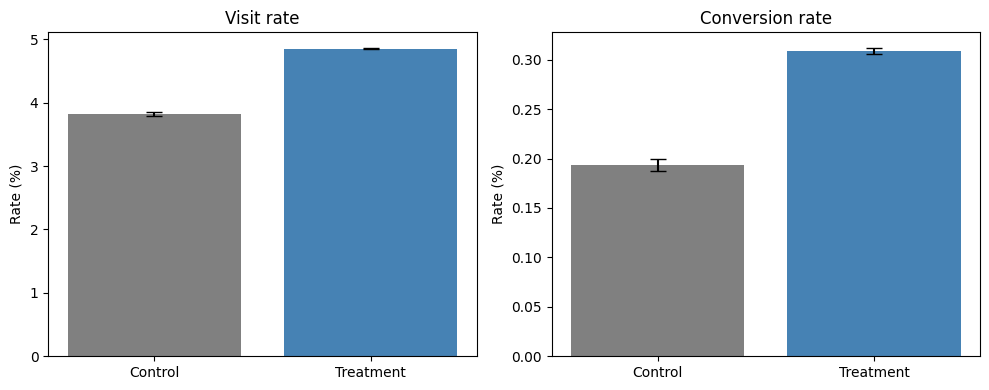

In [21]:
outcomes = ['visit', 'conversion']

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, outcome in zip(axes, outcomes):
    n_t = (df['treatment'] == 1).sum()
    n_c = (df['treatment'] == 0).sum()

    rate_t = df.loc[df['treatment'] == 1, outcome].mean()
    rate_c = df.loc[df['treatment'] == 0, outcome].mean()

    err_t = 1.96 * (rate_t * (1 - rate_t) / n_t) ** 0.5
    err_c = 1.96 * (rate_c * (1 - rate_c) / n_c) ** 0.5

    ax.bar(['Control', 'Treatment'],
           [rate_c * 100, rate_t * 100],
           yerr=[err_c * 100, err_t * 100],
           capsize=6,
           color=['gray', 'steelblue'])
    ax.set_title(f"{outcome.capitalize()} rate")
    ax.set_ylabel("Rate (%)")

plt.tight_layout()
plt.show()

If the confidence intervals included 0, then it is not statistically significant. Both conversion and visit CIs are well above zero, so we can say that being being in the treatment group does increase likelihood of a purchase or webiste visit.

**Increase rate based on targeting:**

Visit - 3.82% to 4.85% (+1.03 pts)
Conversion - 0.19% to 0.31% (+0.12 pts)

*Reminder that this is the intent-to-treat effect and is diluted by the 3.6% exposure rate.*

##Two-proportion Z-test

Most common way to read a conversion rate A/B test.

In [22]:
print(df['conversion'].mean())

0.002916680257907384


In [23]:
exp_results_df = df.groupby('treatment').agg({'conversion':['mean', 'sum', 'count']})
exp_results_df

conversion                 
                mean    sum     count
treatment                            
0           0.001938   4063   2096937
1           0.003089  36711  11882655

In [24]:
print((exp_results_df.loc[1,('conversion', 'mean')]
 - exp_results_df.loc[0,('conversion', 'mean')]).round(4))

0.0012


In [25]:
print(proportions_ztest(count=exp_results_df[('conversion', 'sum')],
                  nobs=exp_results_df[('conversion', 'count')])) ##DO VISITS

(np.float64(-28.516529408977203), np.float64(7.30826328583868e-179))


In [26]:
outcome = 'visit'

events_t = df.loc[df['treatment'] == 1, outcome].sum()
events_c = df.loc[df['treatment'] == 0, outcome].sum()
n_t = (df['treatment'] == 1).sum()
n_c = (df['treatment'] == 0).sum()

z_stat, p_value = proportions_ztest(count=[events_t, events_c], nobs=[n_t, n_c], alternative='two-sided')

print(f"z-statistic = {z_stat}")
print(f"p-value = {p_value}")

z-statistic = 65.24742956249247
p-value = 0.0


In [27]:
outcome = 'conversion'

events_t = df.loc[df['treatment'] == 1, outcome].sum()
events_c = df.loc[df['treatment'] == 0, outcome].sum()
n_t = (df['treatment'] == 1).sum()
n_c = (df['treatment'] == 0).sum()

z_stat, p_value = proportions_ztest(count=[events_t, events_c], nobs=[n_t, n_c], alternative='two-sided')

print(f"z-statistic = {z_stat}")
print(f"p-value = {p_value}")

z-statistic = 28.516529408977203
p-value = 7.30826328583868e-179


p-value is extremely small and less than 0.05 for both visits and conversions. This shows that there is a significant ATE (average treatment response).

###Binning (Segment Analysis)

Does the effect vary across users?

Targeting increases visit rate by 1.03% on average. Does everyone respond about the same or do responses differ? If everyone responds the same, then random targeting would be the best strategy instead of trying to personalize it. This question asks whether it's worth building an uplift model or not.

treatment   control  treatment      lift
1          0.058306   0.071436  0.013131
2          0.084930   0.122724  0.037794
3          0.055280   0.069760  0.014480
4          0.013752   0.016351  0.002599
5          0.020248   0.022686  0.002438
6          0.011233   0.012893  0.001660
7          0.017038   0.017913  0.000874
8          0.007688   0.007953  0.000265


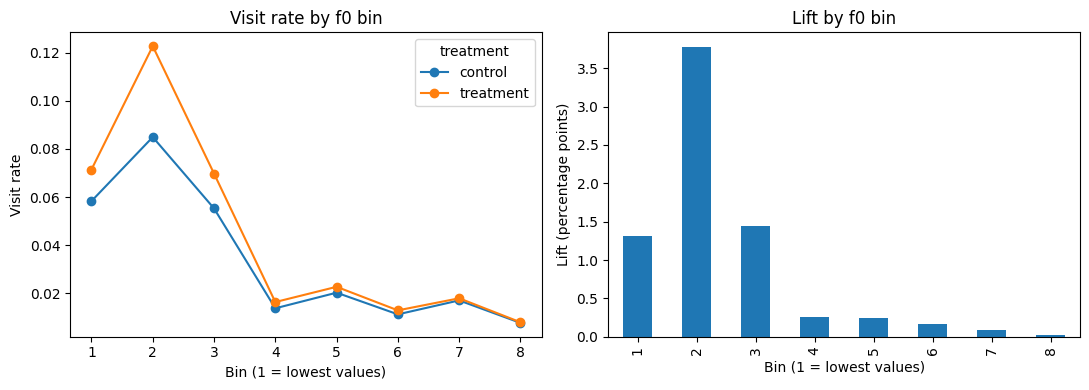

In [28]:
feature = 'f0'

bins = pd.qcut(df[feature], q=10, duplicates='drop') #sorts users equally into 10 bins, drop duplicate values to avoid repeating bin edges

rates = df.groupby([bins, df['treatment']], observed=True)['visit'].mean().unstack() #group by bin and treatment, get visit rate for each group using avg, turn treatment into columns
rates = rates.rename(columns={0: 'control', 1: 'treatment'}) #rename new treatment columns
rates['lift'] = rates['treatment'] - rates['control'] #calculate lift
rates.index = range(1, len(rates) + 1) #rename interval labels to 1,2,3

print(rates)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

rates[['control', 'treatment']].plot(ax=axes[0], marker='o')
axes[0].set_title(f"Visit rate by {feature} bin")
axes[0].set_xlabel("Bin (1 = lowest values)")
axes[0].set_ylabel("Visit rate")

(rates['lift'] * 100).plot(kind='bar', ax=axes[1])
axes[1].set_title(f"Lift by {feature} bin")
axes[1].set_xlabel("Bin (1 = lowest values)")
axes[1].set_ylabel("Lift (percentage points)")

plt.tight_layout()
plt.show()

There's a pretty big gap between bins 1-3 and the increase in lift is concentrated there as well. This looks pretty promising, but first let's check how many of the users were put in each bin to see if most of the users just happen to be in bins 1-3.

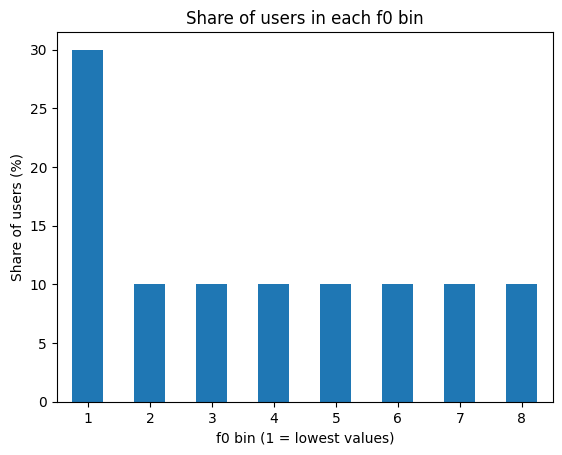

In [29]:
shares = df.groupby(bins, observed=True).size() / len(df) #looks at size of bins
shares.index = range(1, len(shares) + 1) #renames interval label

(shares * 100).plot(kind='bar')
plt.xlabel("f0 bin (1 = lowest values)")
plt.ylabel("Share of users (%)")
plt.title("Share of users in each f0 bin")
plt.xticks(rotation=0)
plt.show()

About 50% of people live in bins 1-3, so it might be why the lifts look concentrated to those bins instead of actually having varied responses. But if more than 50% of the total lift is only attributed to bins 1-3, then the lift is properly concentrated, meaning that the effect varies across people.

In [30]:
shares = df.groupby(bins, observed=True).size() / len(df)
shares.index = range(1, len(shares) + 1)

rates['share'] = shares
rates['lift_contribution'] = rates['share'] * rates['lift']
rates['pct_of_total_lift'] = rates['lift_contribution'] / rates['lift_contribution'].sum() * 100

print(rates[['share', 'lift', 'pct_of_total_lift']])
print(rates['pct_of_total_lift'].iloc[:3].sum())

treatment  share      lift  pct_of_total_lift
1            0.3  0.013131          39.589165
2            0.1  0.037794          37.982706
3            0.1  0.014480          14.552195
4            0.1  0.002599           2.611598
5            0.1  0.002438           2.450365
6            0.1  0.001660           1.668670
7            0.1  0.000874           0.878857
8            0.1  0.000265           0.266444
92.12406531849457


After calculating the % of total lift by bin, we can see that about 92% of the lift is attributed to bins 1-3. Bin 2 shows the most varied effect across people since it carries about 10% of people but 38% of the lift.

Checking another feature with the same method before moving on.

treatment   control  treatment      lift
1          0.091996   0.148187  0.056190
2          0.048935   0.065301  0.016366
3          0.032631   0.039884  0.007253
4          0.023282   0.027331  0.004049
5          0.016508   0.018688  0.002180
6          0.011156   0.012275  0.001119
7          0.051638   0.053334  0.001696


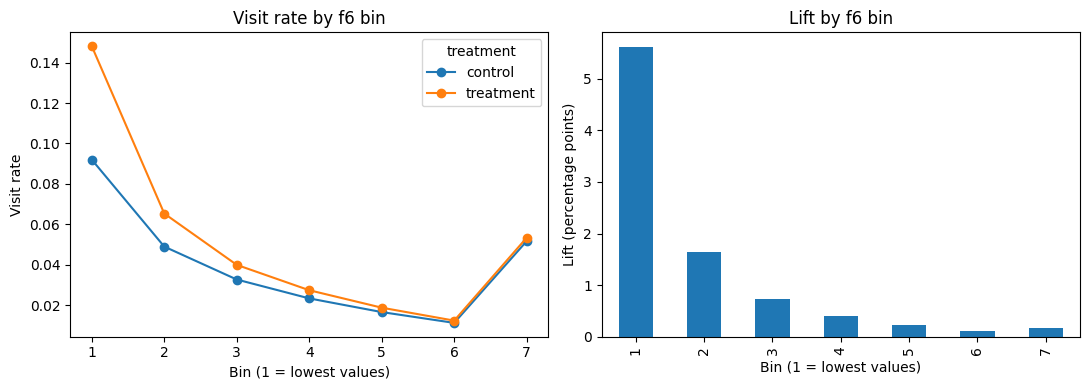

In [31]:
feature = 'f6'

bins = pd.qcut(df[feature], q=10, duplicates='drop') #sorts users equally into 10 bins, drop duplicate values to avoid repeating bin edges

rates = df.groupby([bins, df['treatment']], observed=True)['visit'].mean().unstack() #group by bin and treatment, get visit rate for each group using avg, turn treatment into columns
rates = rates.rename(columns={0: 'control', 1: 'treatment'}) #rename new treatment columns
rates['lift'] = rates['treatment'] - rates['control'] #calculate lift
rates.index = range(1, len(rates) + 1) #rename interval labels to 1,2,3

print(rates)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

rates[['control', 'treatment']].plot(ax=axes[0], marker='o')
axes[0].set_title(f"Visit rate by {feature} bin")
axes[0].set_xlabel("Bin (1 = lowest values)")
axes[0].set_ylabel("Visit rate")

(rates['lift'] * 100).plot(kind='bar', ax=axes[1])
axes[1].set_title(f"Lift by {feature} bin")
axes[1].set_xlabel("Bin (1 = lowest values)")
axes[1].set_ylabel("Lift (percentage points)")

plt.tight_layout()
plt.show()

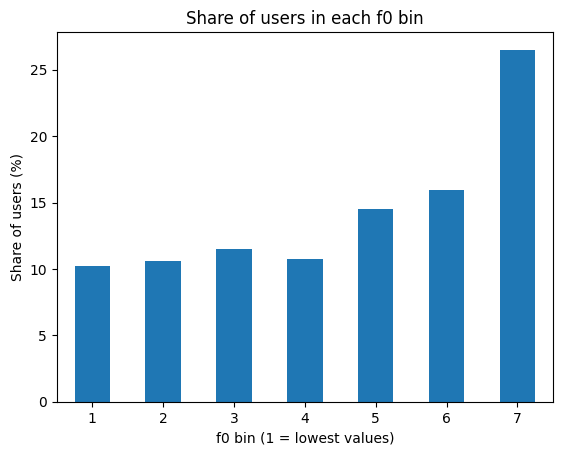

In [32]:
shares = df.groupby(bins, observed=True).size() / len(df) #looks at size of bins
shares.index = range(1, len(shares) + 1) #renames interval label

(shares * 100).plot(kind='bar')
plt.xlabel("f0 bin (1 = lowest values)")
plt.ylabel("Share of users (%)")
plt.title("Share of users in each f0 bin")
plt.xticks(rotation=0)
plt.show()

In [33]:
shares = df.groupby(bins, observed=True).size() / len(df)
shares.index = range(1, len(shares) + 1)

rates['share'] = shares
rates['lift_contribution'] = rates['share'] * rates['lift']
rates['pct_of_total_lift'] = rates['lift_contribution'] / rates['lift_contribution'].sum() * 100

print(rates[['share', 'lift', 'pct_of_total_lift']])
print(rates['pct_of_total_lift'].iloc[:3].sum())

treatment     share      lift  pct_of_total_lift
1          0.102168  0.056190          59.288054
2          0.105754  0.016366          17.874416
3          0.114672  0.007253           8.589366
4          0.107375  0.004049           4.489905
5          0.145267  0.002180           3.271250
6          0.159696  0.001119           1.845301
7          0.265068  0.001696           4.641708
85.75183660862801


f6 is a lot more promising in having varied responses between users. Bin 1 only hold 10% of the people but carries 59% of the lift. Bin 1-3 only carry 30% of the people but carries 86% of the lift. That makes me comfortable enough to move into modeling!

#Model

##Splitting train/test set

I will not resample to balance out the class imbalance of visits and conversions because uplift is computed as a difference between predicted probabilities. I could resample and then rescale afterwards, but for simplicity I will stick to the original proportions. Also, there is enough data to train on visits. For conversions, I would take results with a grain of salt.

In [34]:
from sklearn.model_selection import train_test_split

feature_cols = [f'f{i}' for i in range(12)] #picks out feature columns

df_model = df.sample(n=2000000, random_state=42) #samples 2M rows out of the 14M

train, test = train_test_split(
    df_model,
    test_size=0.3, #70/30 split
    random_state=42,
    stratify=df_model['treatment'] #keep the same treatment/control proportion for each set
)

print(train.shape, test.shape)
print(train['treatment'].mean(), test['treatment'].mean()) #checks if treatment share is the same
print(train['visit'].mean(), test['visit'].mean())

(1400000, 16) (600000, 16)
0.8503835714285715 0.8503833333333334
0.046912857142857145 0.04735


In [35]:
train.groupby('treatment')[['visit', 'conversion']].agg(['count', 'sum'])

visit        conversion      
             count    sum      count   sum
treatment                                 
0           209463   7918     209463   396
1          1190537  57760    1190537  3823

In [36]:
test.groupby('treatment')[['visit', 'conversion']].agg(['count', 'sum'])

visit        conversion      
            count    sum      count   sum
treatment                                
0           89770   3473      89770   181
1          510230  24937     510230  1559